# MoveBench Example: End-to-End Pipeline

This notebook runs the full MoveBench pipeline in Python:

1. Ingest a Movebank-formatted CSV into `data/movebench/studies/<study_id>/`
2. Download rasters for a layer config
3. Extract iSSF point feature stores
4. Compute normalization statistics from point features
5. Create iSSF PyTorch datasets
6. Train/evaluate simple step-selection models (Linear + MLP) and compare to random

Notes:
- Raster download uses Google Earth Engine (EE). Make sure EE auth is set up in your environment.
- This notebook reuses on-disk artifacts when present (skip-existing behavior).


In [1]:
from __future__ import annotations

import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch.utils.data import DataLoader

from movebench import Study
from movebench.models import LinearStepSelect, MLPStepSelect, random_baseline_metrics
from movebench.train import collate_step_select, eval_step_select, fit_step_select


## Configuration

Update these paths/ids as needed.


In [2]:
# --- Study + config ---
STUDY_ID = "tsavo_lions"  # Change this to your study id
LAYER_CONFIG = "../configs/layers_local.yaml"

# --- Ingestion (optional) ---
# Provide a Movebank-formatted CSV to ingest. If it doesn't exist, ingestion is skipped.
movebank_csv = Path("/path/to/movebank_export.csv")  # <-- set this if you want to run ingestion
INGEST_FORCE = False  # set True to overwrite an existing study dir

# --- Download/feature extraction defaults (match scripts/run_issf_benchmark.py) ---
TOP_K_VALUES = (1, 5, 10, 25, 50)
NUM_CANDIDATES = 100
SAMPLER_RANDOM_SEED = 0
STEP_MULTIPLIER = 2.0
STEP_Q = 0.95
GAP_Q = 0.999
BOUNDS_BUFFER_DEG = 0.01

SETUP_WORKERS = 16  # workers for download/extract
BATCH_SIZE = 32
DATALOADER_WORKERS = 0
SEED = 0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cpu')

## 1) Ingestion (Movebank CSV → MoveBench Study)

This step is optional if the study already exists under `data/movebench/studies/<study_id>/`.


In [3]:
# If the study already exists, you can skip ingestion.

try:
    existing = Study(STUDY_ID).study_dir
    print(f"Study already exists: {existing}")
except FileNotFoundError:
    print("Study not found; ingestion can create it.")

if movebank_csv.exists():
    cmd = [
        sys.executable,
        str(REPO_ROOT / "scripts" / "ingest.py"),
        str(movebank_csv),
        "--study-id",
        STUDY_ID,
    ]
    if INGEST_FORCE:
        cmd.append("--force")
    print("Running:", " ".join(cmd))
    subprocess.run(cmd, check=True)
else:
    print(f"Skipping ingest (CSV not found): {movebank_csv}")

study = Study(STUDY_ID)
study.study_dir


Study already exists: /Users/justinkay/movebench/data/movebench/studies/tsavo_lions
Skipping ingest (CSV not found): /path/to/movebank_export.csv


PosixPath('/Users/justinkay/movebench/data/movebench/studies/tsavo_lions')

## 2) Inspect `trajectories.csv`


In [4]:
from movebench.trajectories import INDIVIDUAL_COL, LAT_COL, LON_COL, SET_COL, TIME_COL

df = pd.read_csv(study.trajectories_path)
df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce")
df = df.dropna(subset=[TIME_COL, LAT_COL, LON_COL])

print("n_points:", len(df))
print("n_individuals:", df[INDIVIDUAL_COL].nunique())
print("split counts:", df[SET_COL].value_counts(dropna=False))
df.head()

n_points: 2154
n_individuals: 3
split counts: set
train    1330
test      824
Name: count, dtype: int64


,individual-id,deployment-id,tag-id,study-id,sensor-type-id,individual-local-identifier,tag-local-identifier,individual-taxon-canonical-name,comments,eobs-temperature,location-lat,location-long,timestamp,visible,event-id,split_time,set,point_id
0,220231,1940317,1940316,220229,653,Diana,NaN,Panthera leo,30.0,NaN,-3.839644,38.923761,2005-01-12 00:00:41,True,1715414,2005-11-21 21:00:47,train,0
1,220231,1940317,1940316,220229,653,Diana,NaN,Panthera leo,34.0,NaN,-3.835012,38.924986,2005-01-12 06:00:48,True,1715415,2005-11-21 21:00:47,train,1
2,220231,1940317,1940316,220229,653,Diana,NaN,Panthera leo,31.0,NaN,-3.828839,38.931286,2005-01-12 18:01:24,True,1715416,2005-11-21 21:00:47,train,2
3,220231,1940317,1940316,220229,653,Diana,NaN,Panthera leo,31.0,NaN,-3.875628,38.932911,2005-02-12 00:00:42,True,1715417,2005-11-21 21:00:47,train,3
4,220231,1940317,1940316,220229,653,Diana,NaN,Panthera leo,34.0,NaN,-3.866109,38.955816,2005-02-12 06:03:02,True,1715418,2005-11-21 21:00:47,train,4


## 3) Build LayerPlan


In [5]:
plan = study.layer_plan(LAYER_CONFIG)
print("config_hash:", plan.config_hash)
print("rasters_hash:", plan.rasters_hash)
print("n_layers:", len(plan.layers_in_order))
print("n_channels:", plan.num_channels())
print("chip_groups:", list(plan.chip_groups.keys()))
plan

config_hash: 3569a6b0964f0863
rasters_hash: 623da2dd6c228978
n_layers: 20
n_channels: 74
chip_groups: ['era5', 'modis', 'high_res']


LayerPlan(config_hash='3569a6b0964f0863', rasters_hash='623da2dd6c228978', layers_in_order=['modis_lst', 'modis_vi', 'modis_ndsi', 'modis_bai', 'era5_land', 'era5', 'era5_land_daily', 'dem', 'slope', 'aspect', 'rugosity', 'dist_water', 'orographic_uplift', 'thermal_uplift', 'modis_lc', 'modis_cvf_tree', 'modis_cvf_nontree', 'modis_cvf_nonveg', 'dynamic_world', 'landsat_ndwi'], channels=[Channel(band_id='modis_lst.LST_Day_1km', layer='modis_lst', categorical=False, normalize=True), Channel(band_id='modis_lst.LST_Night_1km', layer='modis_lst', categorical=False, normalize=True), Channel(band_id='modis_vi.NDVI', layer='modis_vi', categorical=False, normalize=True), Channel(band_id='modis_vi.EVI', layer='modis_vi', categorical=False, normalize=True), Channel(band_id='modis_ndsi.NDSI', layer='modis_ndsi', categorical=False, normalize=True), Channel(band_id='modis_bai.BAI', layer='modis_bai', categorical=False, normalize=True), Channel(band_id='era5_land.temperature_2m', layer='era5_land', c

## 4) Download rasters

This downloads any missing GEE rasters required by the layer plan into the study directory.


In [6]:
download_report = study.download_rasters(
    config=LAYER_CONFIG,
    splits=["train", "test"],
    n_workers=SETUP_WORKERS,
    skip_existing=True,
)
download_report


{'config_hash': '3569a6b0964f0863',
 'rasters_hash': '623da2dd6c228978',
 'buffer_km': 19.951364174804187,
 'chips': {'total_points': 2154,
  'downloaded': 0,
  'existing': 6462,
  'failed': 0,
  'failures': []},
 'tiles': {'dem': {'total': 2,
   'downloaded': 0,
   'existing': 2,
   'failed': 0,
   'index_path': '/Users/justinkay/movebench/data/movebench/studies/tsavo_lions/rasters/623da2dd6c228978/tiles/dem/index.json'},
  'dist_water': {'total': 2,
   'downloaded': 0,
   'existing': 2,
   'failed': 0,
   'index_path': '/Users/justinkay/movebench/data/movebench/studies/tsavo_lions/rasters/623da2dd6c228978/tiles/dist_water/index.json'}}}

## 5) Extract iSSF point feature stores (parametric)


In [7]:
extract_report = study.extract_point_features(
    config=LAYER_CONFIG,
    splits=["train", "test"],
    parametric=True,
    num_candidates=NUM_CANDIDATES,
    random_seed=SAMPLER_RANDOM_SEED,
    n_workers=SETUP_WORKERS,
    skip_existing=True,
    step_multiplier=STEP_MULTIPLIER,
    step_q=STEP_Q,
    gap_q=GAP_Q,
    bounds_buffer_deg=BOUNDS_BUFFER_DEG,
)

sampler_hash = extract_report["sampler_hash"]
print("sampler_hash:", sampler_hash)
extract_report


/Users/justinkay/movebench/movebench/trajectories.py:105: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df["valid_step"].shift(-1).fillna(False).astype(bool)
/Users/justinkay/movebench/movebench/trajectories.py:105: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df["valid_step"].shift(-1).fillna(False).astype(bool)
/Users/justinkay/movebench/movebench/trajectories.py:105: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects

sampler_hash: 5ba5b75ea84ba38f


{'study_id': 'tsavo_lions',
 'config_hash': '3569a6b0964f0863',
 'sampler_hash': '5ba5b75ea84ba38f',
 'splits': {'train': {'split': 'train',
   'status': 'written',
   'out_dir': '/Users/justinkay/movebench/data/movebench/studies/tsavo_lions/features/points/train/3569a6b0964f0863/5ba5b75ea84ba38f',
   'n_steps': 1294},
  'test': {'split': 'test',
   'status': 'written',
   'out_dir': '/Users/justinkay/movebench/data/movebench/studies/tsavo_lions/features/points/test/3569a6b0964f0863/5ba5b75ea84ba38f',
   'n_steps': 815}}}

## 6) Compute normalization stats (from point features)


In [8]:
norm_report = study.compute_normalization_vals(
    from_="points",
    config=LAYER_CONFIG,
    sampler_hash=sampler_hash,
    split="train",
    skip_existing=True,
)
norm_report


{'status': 'written',
 'stats_path': '/Users/justinkay/movebench/data/movebench/studies/tsavo_lions/normalization/points/3569a6b0964f0863/5ba5b75ea84ba38f/stats.json',
 'config_hash': '3569a6b0964f0863',
 'sampler_hash': '5ba5b75ea84ba38f',
 'n_bands_normalized': 47,
 'n_steps': 1294,
 'points_per_step': 101}

## 7) Create datasets + loaders


In [9]:
train_ds = study.issf_dataset(
    split="train",
    config=LAYER_CONFIG,
    include_time=False,
    normalize=True,
    num_candidates=NUM_CANDIDATES,
    random_seed=SAMPLER_RANDOM_SEED,
    step_multiplier=STEP_MULTIPLIER,
    step_q=STEP_Q,
    gap_q=GAP_Q,
    bounds_buffer_deg=BOUNDS_BUFFER_DEG,
)

test_ds = study.issf_dataset(
    split="test",
    config=LAYER_CONFIG,
    include_time=False,
    normalize=True,
    num_candidates=NUM_CANDIDATES,
    random_seed=SAMPLER_RANDOM_SEED,
    step_multiplier=STEP_MULTIPLIER,
    step_q=STEP_Q,
    gap_q=GAP_Q,
    bounds_buffer_deg=BOUNDS_BUFFER_DEG,
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=DATALOADER_WORKERS,
    collate_fn=collate_step_select,
    drop_last=False,
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=DATALOADER_WORKERS,
    collate_fn=collate_step_select,
    drop_last=False,
)

x0, valid0 = next(iter(train_loader))
print("batch x shape:", tuple(x0.shape), "valid shape:", tuple(valid0.shape))
print("finite:", torch.isfinite(x0).all().item())


batch x shape: (32, 299, 101) valid shape: (32, 299, 101)
finite: True


## 8) Train + evaluate models (Linear + MLP)

This mirrors `scripts/run_issf_benchmark.py` but runs interactively.


In [12]:
# Determine C,P for model construction and random baseline.
B, C, P = x0.shape
random_metrics = random_baseline_metrics(int(P), TOP_K_VALUES)

# Hyperparameters (same as scripts/run_issf_benchmark.py)
LINEAR_HPARAMS = {
    "lr": 1e-2,
    "weight_decay": 1e-3,
    "max_steps": 1000,
    "eval_interval": 10,
    "patience": 50,
}

MLP_HPARAMS = {
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "max_steps": 2000,
    "eval_interval": 10,
    "patience": 50,
    "hidden_dims": (128,),
    "dropout": 0.6,
}

# --- Linear ---
linear = LinearStepSelect(int(C))
linear_fit = fit_step_select(
    linear,
    train_loader,
    test_loader,
    device,
    seed=SEED,
    **LINEAR_HPARAMS,
)
linear_train = eval_step_select(linear, train_loader, device, topk=TOP_K_VALUES)
linear_test = eval_step_select(linear, test_loader, device, topk=TOP_K_VALUES)

# --- MLP ---
mlp = MLPStepSelect(int(C), hidden_dims=MLP_HPARAMS["hidden_dims"], dropout=MLP_HPARAMS["dropout"])
mlp_fit = fit_step_select(
    mlp,
    train_loader,
    test_loader,
    device,
    seed=SEED,
    lr=float(MLP_HPARAMS["lr"]),
    weight_decay=float(MLP_HPARAMS["weight_decay"]),
    max_steps=int(MLP_HPARAMS["max_steps"]),
    eval_interval=int(MLP_HPARAMS["eval_interval"]),
    patience=int(MLP_HPARAMS["patience"]),
)
mlp_train = eval_step_select(mlp, train_loader, device, topk=TOP_K_VALUES)
mlp_test = eval_step_select(mlp, test_loader, device, topk=TOP_K_VALUES)

results = {
    "study": STUDY_ID,
    "config": str(LAYER_CONFIG),
    "P": int(P),
    "random": random_metrics,
    "linear": {"fit": linear_fit, "train": linear_train, "test": linear_test},
    "mlp": {"fit": mlp_fit, "train": mlp_train, "test": mlp_test},
}

results


{'study': 'tsavo_lions',
 'config': '../configs/layers_local.yaml',
 'P': 101,
 'random': {'nll': 4.61512051684126,
  'topk': {1: 0.009900990099009901,
   5: 0.04950495049504951,
   10: 0.09900990099009901,
   25: 0.24752475247524752,
   50: 0.49504950495049505}},
 'linear': {'fit': {'best_step': 60,
   'train': {'nll': 4.351334706708858,
    'topk': {1: 0.03245749613601236,
     5: 0.15069551777434312,
     10: 0.26197836166924265,
     25: 0.4868624420401855,
     50: 0.7534775888717156}},
   'val': {'nll': 4.611137118661331,
    'topk': {1: 0.026993865030674847,
     5: 0.09815950920245399,
     10: 0.16441717791411042,
     25: 0.37055214723926383,
     50: 0.649079754601227}},
   'history': [{'step': 0.0,
     'train_nll': 4.6677859960788926,
     'val_nll': 4.631267965351877},
    {'step': 10.0,
     'train_nll': 4.480902971034809,
     'val_nll': 4.629382390332368},
    {'step': 20.0,
     'train_nll': 4.431482885499273,
     'val_nll': 4.612890936260574},
    {'step': 30.0,
   

## 9) Plot results


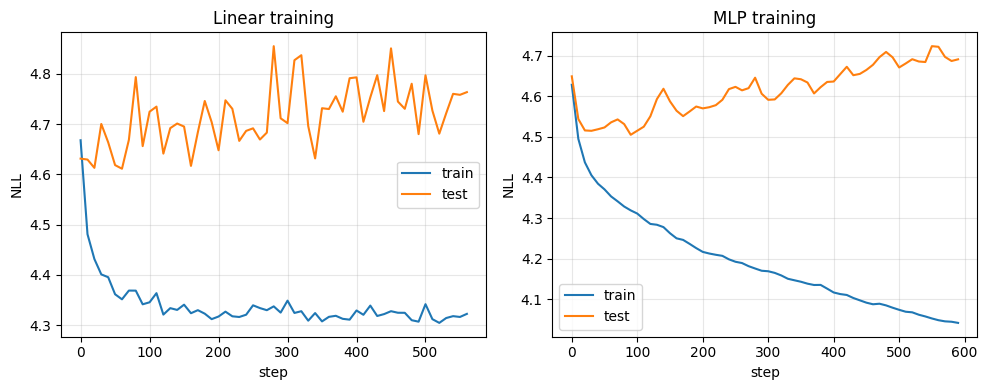

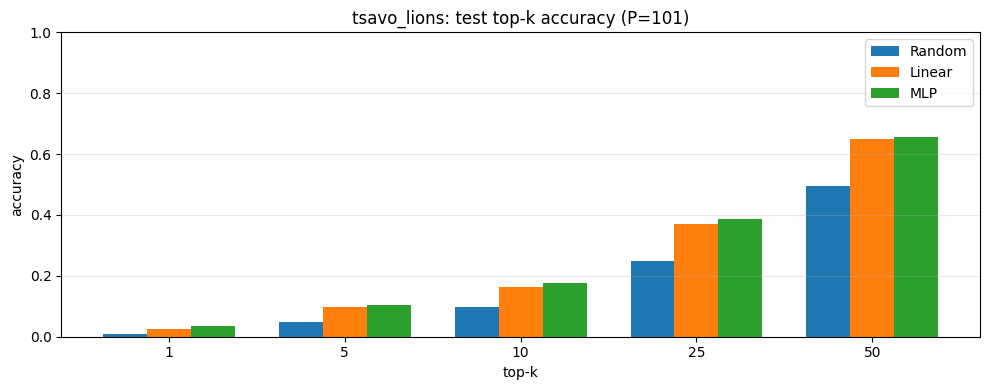

,Random,Linear,MLP
split,,,
train,4.615121,4.351335,4.318921
test,4.615121,4.611137,4.505118


In [13]:
def _plot_history(hist, title: str):
    if not hist:
        print(f"No history for {title}")
        return
    h = pd.DataFrame(hist)
    plt.plot(h["step"], h["train_nll"], label="train")
    plt.plot(h["step"], h["val_nll"], label="test")
    plt.title(title)
    plt.xlabel("step")
    plt.ylabel("NLL")
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
_plot_history(results["linear"]["fit"]["history"], "Linear training")
plt.subplot(1, 2, 2)
_plot_history(results["mlp"]["fit"]["history"], "MLP training")
plt.tight_layout()
plt.show()

# Top-k accuracy bar plot on test split
ks = list(TOP_K_VALUES)
acc_random = [results["random"]["topk"][k] for k in ks]
acc_linear = [results["linear"]["test"]["topk"][k] for k in ks]
acc_mlp = [results["mlp"]["test"]["topk"][k] for k in ks]

x = range(len(ks))
w = 0.25
plt.figure(figsize=(10, 4))
plt.bar([i - w for i in x], acc_random, width=w, label="Random")
plt.bar([i for i in x], acc_linear, width=w, label="Linear")
plt.bar([i + w for i in x], acc_mlp, width=w, label="MLP")
plt.xticks(list(x), [str(k) for k in ks])
plt.xlabel("top-k")
plt.ylabel("accuracy")
plt.title(f"{STUDY_ID}: test top-k accuracy (P={P})")
plt.ylim(0, 1)
plt.grid(True, axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# NLL summary table
rows = [
    {
        "split": "train",
        "Random": results["random"]["nll"],
        "Linear": results["linear"]["train"]["nll"],
        "MLP": results["mlp"]["train"]["nll"],
    },
    {
        "split": "test",
        "Random": results["random"]["nll"],
        "Linear": results["linear"]["test"]["nll"],
        "MLP": results["mlp"]["test"]["nll"],
    },
]

pd.DataFrame(rows).set_index("split")
